In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import sys
import nbformat

print("Python:", sys.executable)
print("nbformat:", nbformat.__version__)

# Load cleaned sales data
sales = pd.read_csv(
    "data/cleaned_datasets/fact_sales_clean.csv"
)

# Convert order date
sales["order_datetime"] = pd.to_datetime(
    sales["order_datetime"],
    errors="coerce"
)

# Create month
sales["month"] = sales["order_datetime"].dt.to_period("M")

# Create gross sales
sales["gross_sales"] = (
    sales["quantity"] * sales["unit_price_at_purchase"]
)

print("Dataset shape:", sales.shape)
print(sales.columns.tolist())
display(sales.head())

Python: c:\Users\Dell\AppData\Local\Programs\Python\Python314\python.exe
nbformat: 5.11.1
Dataset shape: (37501, 34)
['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price_at_purchase', 'customer_id', 'order_datetime', 'order_status', 'sales_channel', 'shipping_method', 'discount_pct', 'shipping_fee', 'product_name', 'brand', 'category', 'unit_cost', 'unit_price', 'stock_qty', 'uom', 'launch_date', 'first_name', 'last_name', 'gender', 'age', 'email', 'phone', 'region_code', 'region_name', 'city', 'barangay', 'signup_date', 'loyalty_tier', 'month', 'gross_sales']


,order_item_id,order_id,product_id,quantity,unit_price_at_purchase,customer_id,order_datetime,order_status,sales_channel,shipping_method,...,email,phone,region_code,region_name,city,barangay,signup_date,loyalty_tier,month,gross_sales
0,ITEM000000001,ORD0000001,PROD00513,2,120.67,CUST000839,2025-11-07 17:02:00,Cancelled,Marketplace,Standard,...,jose.reyes@mail.com,9.110005e+09,Region X,Northern Mindanao,Iligan,Brgy 10,2025-04-21,Bronze,2025-11,241.34
1,ITEM000000002,ORD0000002,PROD00124,2,83.58,CUST002871,2025-09-18 09:13:00,Completed,Marketplace,Express,...,noah.bautista@gmail.com,9.633707e+08,Region VII,Central Visayas,Mandaue,Brgy 5,2023-03-18,Gold,2025-09,167.16
2,ITEM000000003,ORD0000002,PROD00631,2,46.96,CUST002871,2025-09-18 09:13:00,Completed,Marketplace,Express,...,noah.bautista@gmail.com,9.633707e+08,Region VII,Central Visayas,Mandaue,Brgy 5,2023-03-18,Gold,2025-09,93.92
3,ITEM000000004,ORD0000002,PROD00136,1,100.59,CUST002871,2025-09-18 09:13:00,Completed,Marketplace,Express,...,noah.bautista@gmail.com,9.633707e+08,Region VII,Central Visayas,Mandaue,Brgy 5,2023-03-18,Gold,2025-09,100.59
4,ITEM000000005,ORD0000002,PROD00090,1,109.18,CUST002871,2025-09-18 09:13:00,Completed,Marketplace,Express,...,noah.bautista@gmail.com,9.633707e+08,Region VII,Central Visayas,Mandaue,Brgy 5,2023-03-18,Gold,2025-09,109.18


In [2]:
print("FULFILLED SALES DATA")
print("=" * 50)

fulfilled = sales[
    sales["order_status"].isin(["Completed", "Shipped"])
].copy()

print("Fulfilled records:", len(fulfilled))
print("Distinct fulfilled orders:", fulfilled["order_id"].nunique())
print("-" * 50)

display(fulfilled.head())

FULFILLED SALES DATA
Fulfilled records: 29220
Distinct fulfilled orders: 11658
--------------------------------------------------


,order_item_id,order_id,product_id,quantity,unit_price_at_purchase,customer_id,order_datetime,order_status,sales_channel,shipping_method,...,email,phone,region_code,region_name,city,barangay,signup_date,loyalty_tier,month,gross_sales
1,ITEM000000002,ORD0000002,PROD00124,2,83.58,CUST002871,2025-09-18 09:13:00,Completed,Marketplace,Express,...,noah.bautista@gmail.com,963370695.0,Region VII,Central Visayas,Mandaue,Brgy 5,2023-03-18,Gold,2025-09,167.16
2,ITEM000000003,ORD0000002,PROD00631,2,46.96,CUST002871,2025-09-18 09:13:00,Completed,Marketplace,Express,...,noah.bautista@gmail.com,963370695.0,Region VII,Central Visayas,Mandaue,Brgy 5,2023-03-18,Gold,2025-09,93.92
3,ITEM000000004,ORD0000002,PROD00136,1,100.59,CUST002871,2025-09-18 09:13:00,Completed,Marketplace,Express,...,noah.bautista@gmail.com,963370695.0,Region VII,Central Visayas,Mandaue,Brgy 5,2023-03-18,Gold,2025-09,100.59
4,ITEM000000005,ORD0000002,PROD00090,1,109.18,CUST002871,2025-09-18 09:13:00,Completed,Marketplace,Express,...,noah.bautista@gmail.com,963370695.0,Region VII,Central Visayas,Mandaue,Brgy 5,2023-03-18,Gold,2025-09,109.18
5,ITEM000000006,ORD0000002,PROD00022,2,54.41,CUST002871,2025-09-18 09:13:00,Completed,Marketplace,Express,...,noah.bautista@gmail.com,963370695.0,Region VII,Central Visayas,Mandaue,Brgy 5,2023-03-18,Gold,2025-09,108.82


GROSS SALES BY PRODUCT CATEGORY


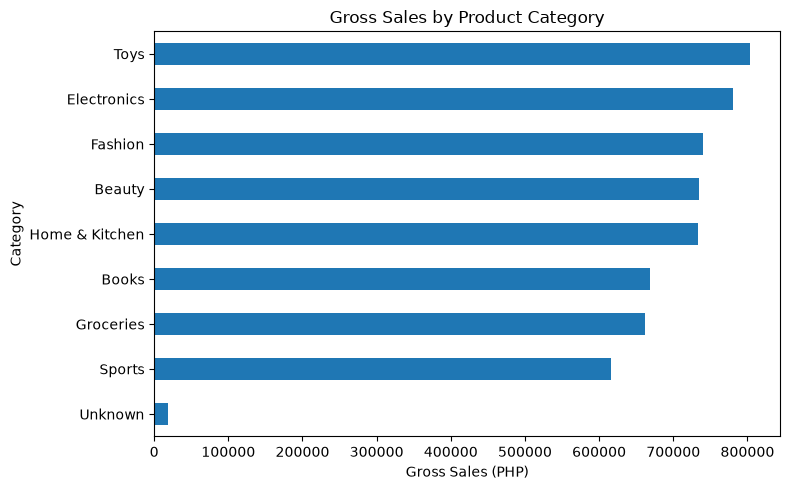

In [3]:
print("GROSS SALES BY PRODUCT CATEGORY")
print("=" * 50)

category_sales = (
    fulfilled.groupby("category")["gross_sales"]
    .sum()
    .sort_values(ascending=True)
)

ax = category_sales.plot(
    kind="barh",
    figsize=(8, 5)
)

ax.set_title("Gross Sales by Product Category")
ax.set_xlabel("Gross Sales (PHP)")
ax.set_ylabel("Category")

plt.tight_layout()
plt.show()

**Interpretation:**

Toys generated the highest gross sales, followed closely by Electronics and Fashion. Sports recorded the lowest gross sales among the recognized product categories. The Unknown category contributed very little to total gross sales.

MONTHLY GROSS SALES TREND


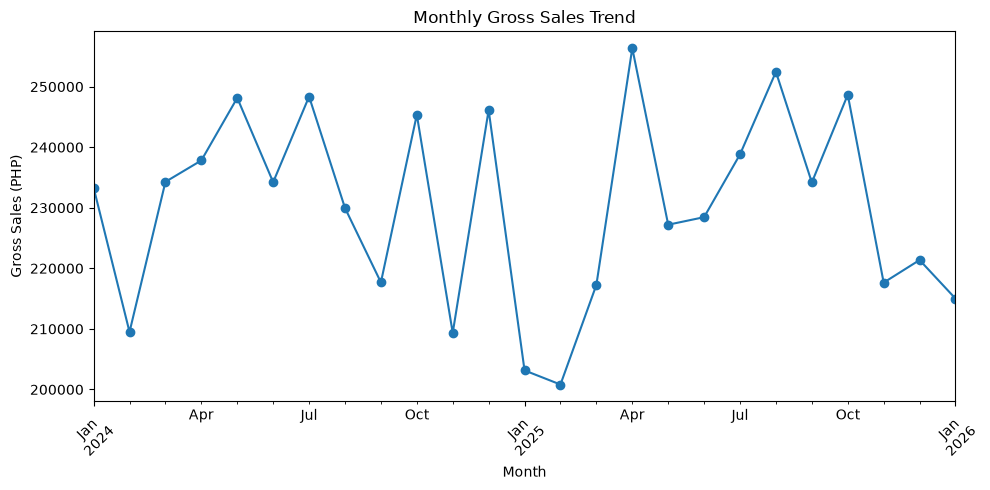

In [4]:
print("MONTHLY GROSS SALES TREND")
print("=" * 50)

monthly_sales = (
    fulfilled.groupby("month")["gross_sales"]
    .sum()
    .sort_index()
)

monthly_sales.plot(
    kind="line",
    figsize=(10, 5),
    marker="o"
)

plt.title("Monthly Gross Sales Trend")
plt.xlabel("Month")
plt.ylabel("Gross Sales (PHP)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

**Interpretation:**

Monthly gross sales fluctuated throughout the period from January 2024 to January 2026. The highest sales occurred in April 2025, while the lowest occurred in February 2025. The trend shows inconsistent monthly sales performance rather than steady growth.

In [5]:
print("ORDER VALUE SUMMARY")
print("=" * 50)

orders_summary = (
    fulfilled.groupby("order_id")
    .agg(
        order_value=("gross_sales", "sum"),
        sales_channel=("sales_channel", "first")
    )
    .reset_index()
)

print("Total fulfilled orders:", len(orders_summary))
print("-" * 50)

display(orders_summary.head())

ORDER VALUE SUMMARY
Total fulfilled orders: 11658
--------------------------------------------------


,order_id,order_value,sales_channel
0,ORD0000002,579.67,Marketplace
1,ORD0000003,527.17,Web
2,ORD0000004,604.51,Web
3,ORD0000005,228.01,Marketplace
4,ORD0000006,560.51,Mobile App


DISTRIBUTION OF ORDER VALUE


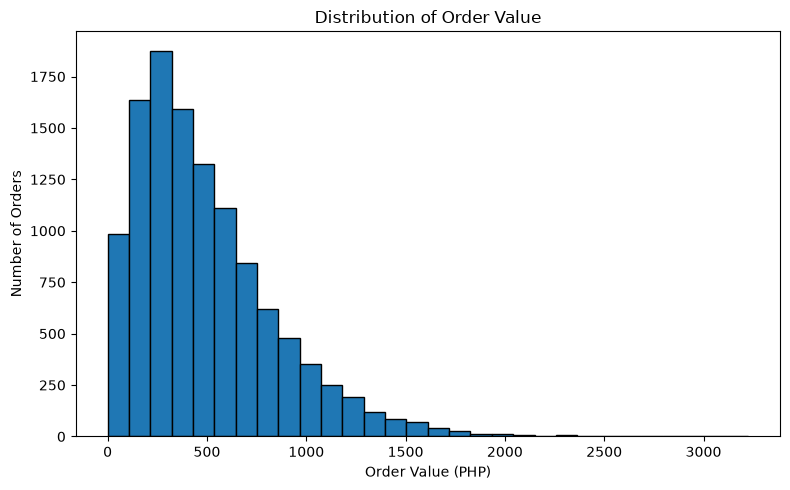

In [10]:
print("DISTRIBUTION OF ORDER VALUE")
print("=" * 50)

plt.figure(figsize=(8, 5))

plt.hist(
    orders_summary["order_value"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Order Value")
plt.xlabel("Order Value (PHP)")
plt.ylabel("Number of Orders")

plt.tight_layout()
plt.show()

**Interpretation:**

Most fulfilled orders have values concentrated below PHP 1,000, with the highest frequency appearing around the PHP 200–400 range. The distribution is right-skewed, indicating that relatively few orders have substantially higher values.

ORDER VALUE BY SALES CHANNEL


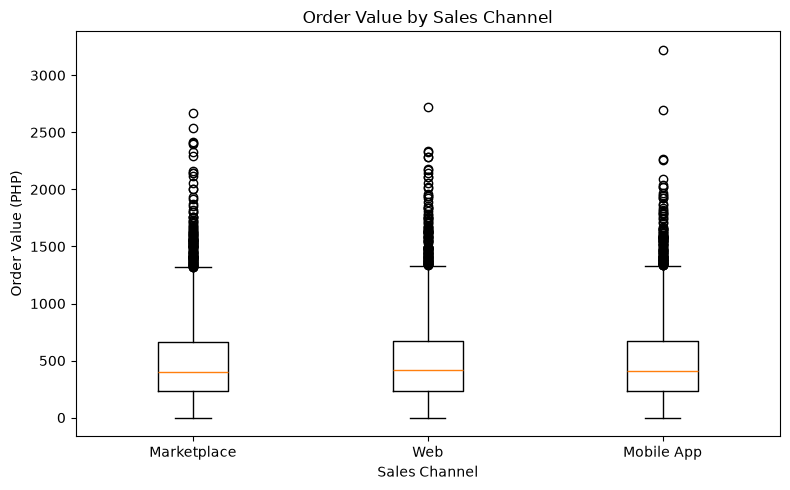

In [29]:
print("ORDER VALUE BY SALES CHANNEL")
print("=" * 50)

channels = orders_summary["sales_channel"].dropna().unique()

values = [
    orders_summary.loc[
        orders_summary["sales_channel"] == channel,
        "order_value"
    ]
    for channel in channels
]

plt.figure(figsize=(8, 5))

plt.boxplot(
    values,
    tick_labels=channels
)

plt.title("Order Value by Sales Channel")
plt.xlabel("Sales Channel")
plt.ylabel("Order Value (PHP)")

plt.tight_layout()
plt.show()

**Interpretation:**

The interactive Plotly chart presents gross sales by product category using the same data as Chart 1. Its hover functionality allows users to inspect the exact gross sales value for each category, making the visualization more interactive and informative.

In [30]:
print("DASHBOARD KPIs")
print("=" * 50)

# 1. Total Sales
total_sales = fulfilled["gross_sales"].sum()

# 2. Total Orders
total_orders = orders_summary["order_id"].nunique()

# 3. Average Order Value
average_order_value = orders_summary["order_value"].mean()

# 4. Top Category
top_category = (
    fulfilled.groupby("category")["gross_sales"]
    .sum()
    .idxmax()
)

print(f"Total Sales: PHP {total_sales:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Average Order Value: PHP {average_order_value:,.2f}")
print(f"Top Category: {top_category}")

DASHBOARD KPIs
Total Sales: PHP 5,755,430.95
Total Orders: 11,658
Average Order Value: PHP 493.69
Top Category: Toys


In [ ]:
**Interpretation:**

The interactive Plotly chart presents gross sales by product category using the same data as Chart 1. Its hover functionality allows users to inspect the exact gross sales value for each category, making the visualization more interactive and informative.